In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

In [2]:
df = pd.read_csv("../data/socmed_inf.csv")

df.shape

(1000, 8)

In [3]:
df.columns

Index(['S.no', 'Tiktoker name', 'Tiktok name', 'Subscribers', 'Views avg.',
       'Likes avg.', 'Comments avg.', 'Shares avg.'],
      dtype='str')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   S.no           1000 non-null   int64
 1   Tiktoker name  1000 non-null   str  
 2   Tiktok name    999 non-null    str  
 3   Subscribers    1000 non-null   str  
 4   Views avg.     1000 non-null   str  
 5   Likes avg.     1000 non-null   str  
 6   Comments avg.  1000 non-null   str  
 7   Shares avg.    1000 non-null   str  
dtypes: int64(1), str(7)
memory usage: 62.6 KB


In [5]:
df.describe()

,S.no
count,1000.000000
mean,500.500000
std,288.819436
min,1.000000
25%,250.750000
50%,500.500000
75%,750.250000
max,1000.000000


In [6]:
df.isnull().sum()

S.no             0
Tiktoker name    0
Tiktok name      1
Subscribers      0
Views avg.       0
Likes avg.       0
Comments avg.    0
Shares avg.      0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
def convert_number(value):
    if pd.isna(value):
        return np.nan
    
    value = str(value).strip().replace(",", "")
    
    if value.upper().endswith("K"):
        return float(value[:-1]) * 1_000
    
    elif value.upper().endswith("M"):
        return float(value[:-1]) * 1_000_000
    
    elif value.upper().endswith("B"):
        return float(value[:-1]) * 1_000_000_000
    
    else:
        return float(value)


In [9]:
numeric_columns = [
    "Subscribers",
    "Views avg.",
    "Likes avg.",
    "Comments avg.",
    "Shares avg."
]

for column in numeric_columns:
    df[column] = df[column].apply(convert_number)

df.head()

,S.no,Tiktoker name,Tiktok name,Subscribers,Views avg.,Likes avg.,Comments avg.,Shares avg.
0,1,jypestraykids,Stray Kids,13800000.0,6400000.0,2300000.0,50200.0,34200.0
1,2,khaby.lame,Khabane lame,149200000.0,17300000.0,2300000.0,15200.0,8700.0
2,3,scarlettsspam2,scarlett,2100000.0,17900000.0,845800.0,53900.0,6300.0
3,4,addisonre,Addison Rae,88700000.0,22000000.0,906600.0,7600.0,26200.0
4,5,belindatok,Belinda,4800000.0,14200000.0,1500000.0,14500.0,15300.0


In [24]:
df.describe()

,S.no,Subscribers,Views avg.,Likes avg.,Comments avg.,Shares avg.
count,1000.000000,1.000000e+03,1.000000e+03,1.000000e+03,1000.000000,1000.000000
mean,500.500000,7.083611e+06,2.854531e+06,3.524345e+05,2540.129000,3263.483000
std,288.819436,1.160618e+07,2.216005e+06,2.861912e+05,3691.868047,4778.561596
min,1.000000,5.100000e+03,5.038000e+05,1.760000e+04,0.000000,70.000000
25%,250.750000,1.300000e+06,1.600000e+06,1.899000e+05,985.000000,822.500000
50%,500.500000,3.500000e+06,2.200000e+06,2.747000e+05,1600.000000,1800.000000
75%,750.250000,8.100000e+06,3.325000e+06,4.007250e+05,2700.000000,3725.000000
max,1000.000000,1.492000e+08,2.200000e+07,2.700000e+06,53900.000000,55900.000000


In [25]:
df["Engagement Rate"] = (
    (df["Likes avg."] +
     df["Comments avg."] +
     df["Shares avg."])
    / df["Views avg."]
) * 100

df[
    [
        "Tiktoker name",
        "Views avg.",
        "Likes avg.",
        "Comments avg.",
        "Shares avg.",
        "Engagement Rate"
    ]
].head()

,Tiktoker name,Views avg.,Likes avg.,Comments avg.,Shares avg.,Engagement Rate
0,jypestraykids,6400000.0,2300000.0,50200.0,34200.0,37.256250
1,khaby.lame,17300000.0,2300000.0,15200.0,8700.0,13.432948
2,scarlettsspam2,17900000.0,845800.0,53900.0,6300.0,5.061453
3,addisonre,22000000.0,906600.0,7600.0,26200.0,4.274545
4,belindatok,14200000.0,1500000.0,14500.0,15300.0,10.773239


In [26]:
top_subscribers = df.sort_values(
    "Subscribers",
    ascending=False
)

top_subscribers[
    ["Tiktoker name", "Tiktok name", "Subscribers"]
].head(10)

,Tiktoker name,Tiktok name,Subscribers
1,khaby.lame,Khabane lame,149200000.0
10,charlidamelio,charli d’amelio,146200000.0
74,bellapoarch,Bella Poarch,91400000.0
3,addisonre,Addison Rae,88700000.0
19,kimberly.loaiza,Kimberly Loaiza,67200000.0
326,cznburak,cznburak,63600000.0
16,domelipa,domelipa,58100000.0
630,dixiedamelio,dixie,57400000.0
6,therock,The Rock,55400000.0
497,lorengray,Loren Gray,54600000.0


In [27]:
top_views = df.sort_values(
    "Views avg.",
    ascending=False
)

top_views[
    ["Tiktoker name", "Tiktok name", "Views avg."]
].head(10)

,Tiktoker name,Tiktok name,Views avg.
3,addisonre,Addison Rae,22000000.0
2,scarlettsspam2,scarlett,17900000.0
1,khaby.lame,Khabane lame,17300000.0
7,bizarrap,bzrp,16200000.0
10,charlidamelio,charli d’amelio,15200000.0
4,belindatok,Belinda,14200000.0
30,rosalia,La Rosalia,14200000.0
35,winnermaxyt,WinnerMax,13800000.0
215,guide_smis,ไกค์ 'สมิท,13100000.0
6,therock,The Rock,13100000.0


In [28]:
top_engagement = df.sort_values(
    "Engagement Rate",
    ascending=False
)

top_engagement[
    [
        "Tiktoker name",
        "Subscribers",
        "Views avg.",
        "Engagement Rate"
    ]
].head(10)

,Tiktoker name,Subscribers,Views avg.,Engagement Rate
0,jypestraykids,13800000.0,6400000.0,37.256250
289,straykids_japan,8100000.0,1000000.0,35.640000
146,seventeen17_official,6000000.0,1900000.0,31.857895
558,avascreams,705000.0,1200000.0,31.336583
759,worldofxtra,806200.0,943600.0,31.157270
814,jeonifty,250000.0,800400.0,29.997501
21,txt.bighitent,18100000.0,3800000.0,29.918421
219,alexitoxedits,2900000.0,1600000.0,29.712500
170,cocielo,5000000.0,2300000.0,29.652174
732,greatekyroga,1100000.0,1100000.0,29.381818


In [29]:
df["View-to-Subscriber Ratio"] = (
    df["Views avg."] / df["Subscribers"]
)

In [30]:
df.sort_values(
    "View-to-Subscriber Ratio",
    ascending=False
)[
    [
        "Tiktoker name",
        "Subscribers",
        "Views avg.",
        "View-to-Subscriber Ratio"
    ]
].head(10)

,Tiktoker name,Subscribers,Views avg.,View-to-Subscriber Ratio
190,wilmah10,6300.0,2900000.0,460.317460
244,straange_56guuuuy,5900.0,1500000.0,254.237288
307,meganfitton6,8700.0,2000000.0,229.885057
776,soapinmymouthoncemore,5100.0,943300.0,184.960784
552,oliviadearlove2,17400.0,3000000.0,172.413793
206,iamprisleeciyi,13900.0,2300000.0,165.467626
530,iloveyourmomscatt,8200.0,1300000.0,158.536585
339,ajkhiphop,36500.0,4600000.0,126.027397
265,kyleechoi,19800.0,1800000.0,90.909091
62,charl1d4meli0,64600.0,5400000.0,83.591331


In [31]:
analysis_columns = [
    "Subscribers",
    "Views avg.",
    "Likes avg.",
    "Comments avg.",
    "Shares avg.",
    "Engagement Rate"
]

correlation = df[analysis_columns].corr()

correlation

,Subscribers,Views avg.,Likes avg.,Comments avg.,Shares avg.,Engagement Rate
Subscribers,1.000000,0.461304,0.362390,0.179816,-0.046565,-0.084020
Views avg.,0.461304,1.000000,0.746352,0.409934,0.144913,-0.240559
Likes avg.,0.362390,0.746352,1.000000,0.462920,0.119060,0.306576
Comments avg.,0.179816,0.409934,0.462920,1.000000,0.246673,0.137617
Shares avg.,-0.046565,0.144913,0.119060,0.246673,1.000000,-0.043106
Engagement Rate,-0.084020,-0.240559,0.306576,0.137617,-0.043106,1.000000


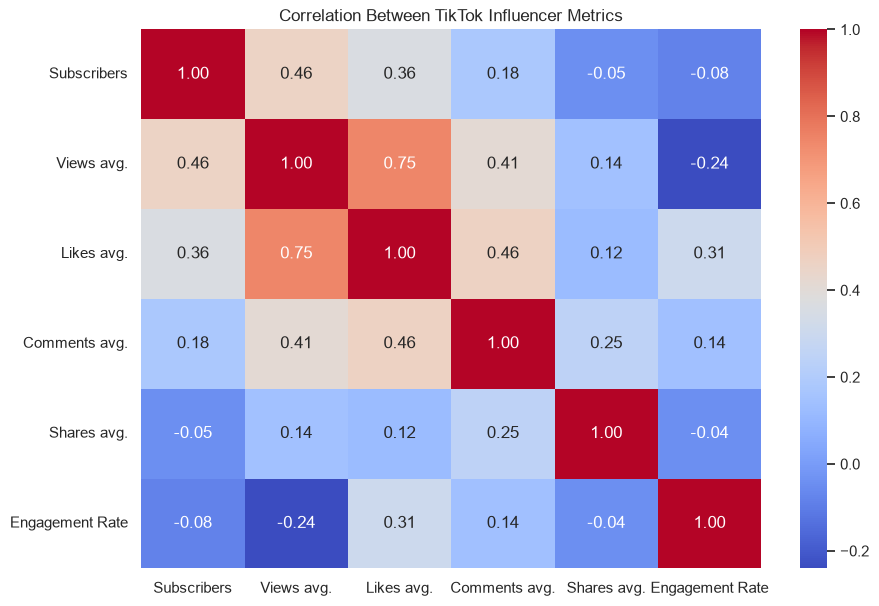

In [32]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between TikTok Influencer Metrics")
plt.show()

In [ ]:
import pandas as pd

df = pd.read_csv("../data/socmed_inf.csv")

print("Dataset shape:", df.shape)
print("Duplicates:", df.duplicated().sum()) #for duplicated value

Dataset shape: (1000, 8)
Duplicates: 0


In [ ]:
print("Missing Values:")
print(df.isna().sum())   #for missing values


Missing Values:
S.no             0
Tiktoker name    0
Tiktok name      1
Subscribers      0
Views avg.       0
Likes avg.       0
Comments avg.    0
Shares avg.      0
dtype: int64


In [11]:
df["Tiktok name"] = df["Tiktok name"].fillna("Unknown")

print("Missing Values After Cleaning:")
print(df.isna().sum())

Missing Values After Cleaning:
S.no             0
Tiktoker name    0
Tiktok name      0
Subscribers      0
Views avg.       0
Likes avg.       0
Comments avg.    0
Shares avg.      0
dtype: int64


In [12]:
print("Missing Values:")
print(df.isna().sum())

Missing Values:
S.no             0
Tiktoker name    0
Tiktok name      0
Subscribers      0
Views avg.       0
Likes avg.       0
Comments avg.    0
Shares avg.      0
dtype: int64


In [13]:
print(df.tail(5))

     S.no Tiktoker name    Tiktok name Subscribers Views avg. Likes avg.  \
995   996  brendadialoy  Brenda Dialoy      371.9K       1.2M     187.5K   
996   997   jujufitcats   Juju Fitcats        4.3M       2.2M     280.8K   
997   998        xoteam        XO Team       37.8M       2.5M     180.2K   
998   999      kimsnwuo             ️️      100.9K     957.4K     226.8K   
999  1000      jass_mcg       jass_mcg       52.2K     503.8K       116K   

    Comments avg. Shares avg.  
995           626          2K  
996           380         558  
997           859         450  
998           908        1.7K  
999          8.1K        1.8K  
